<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Entropy: 1.459147917027245

 Model A
Cross Entropy: 1.459219581559488
KL Divergence: 7.166453224309848e-05
Entropy + KL: 1.4592195815594882

 Model B
Cross Entropy: 1.5849173005252268
KL Divergence: 0.1257693834979821
Entropy + KL: 1.584917300525227

Verification:
Cross Entropy = 1.4592195815594882

KL(True || Model A): 7.166453224309848e-05
KL(Model A || True): 7.18978740631834e-05


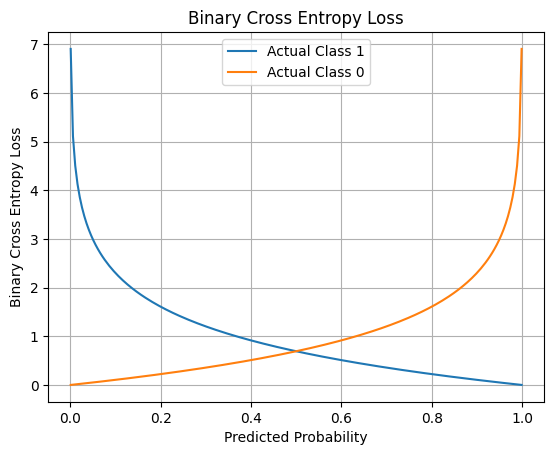

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# Actual Weather Distribution (30 days)
true = np.array([15,10,5]) / 30

# Two Prediction Models
model_A = np.array([0.50,0.33,0.17])
model_B = np.array([0.70,0.20,0.10])

# 1. Entropy
H = entropy(true, base=2)

print("Entropy:", H)

# 2. Cross Entropy and KL Divergence
def cross_entropy(p,q):
    return -np.sum(p*np.log2(q))

def kl_divergence(p,q):
    return np.sum(p*np.log2(p/q))

for name, model in [
    ("Model A",model_A),
    ("Model B",model_B)
]:
    CE = cross_entropy(true,model)
    KL = kl_divergence(true,model)

    print("\n",name)
    print("Cross Entropy:",CE)
    print("KL Divergence:",KL)
    print("Entropy + KL:",H+KL)

# 3. Verify the relationship
print("\nVerification:")
print("Cross Entropy =", H + kl_divergence(true,model_A))

# 4. KL Divergence Asymmetry
print("\nKL(True || Model A):",
      kl_divergence(true,model_A))

print("KL(Model A || True):",
      kl_divergence(model_A,true))

# 5. Binary Cross Entropy
p = np.linspace(0.001,0.999,200)

loss1 = -np.log(p)
loss0 = -np.log(1-p)

plt.plot(p,loss1,label="Actual Class 1")
plt.plot(p,loss0,label="Actual Class 0")

plt.xlabel("Predicted Probability")
plt.ylabel("Binary Cross Entropy Loss")
plt.title("Binary Cross Entropy Loss")
plt.legend()
plt.grid()
plt.show()